# 1. Apoptosis Timing & Scanning BCL2 (Norris *et al.* Figure 1B)

In Tutorials 3 and 4, we modelled how upstream receptors (**BCR**, **TLR**, and **NIK**) activate **NF-κB** transcription factors in B-cell lymphoma. Those signalling pathways matter clinically because they ultimately control **cell fate**: whether a lymphoma cell **dies** (apoptosis) or **divides** (the cell cycle).

In this tutorial, we build the two single-cell fate models from *Norris, Jones, Mancini, Chevassut, Simoes, Pepper, Pepper & Mitchell* (**Blood Cancer Journal**, 2024, 14:105, [doi:10.1038/s41408-024-01090-y](https://www.nature.com/articles/s41408-024-01090-y)) — recreating **Figure 1B** (apoptosis timing vs **BCL2**) here, and **Figure 1E** (cell-cycle timing vs **c-MYC**) in Chapter 2. Measuring **time to death** and **time to division** in individual cells lays the foundation for **multiscale modelling** in the next tutorial, where whole populations of virtual B-cells compete between dividing and dying.

```{figure} ../images/cell-fate-to-multiscale.svg
:alt: Diagram showing how the single-cell apoptosis clock (BCL2) and cell-cycle clock (c-MYC) combine in Double-Hit Lymphoma and prepare for multiscale modelling
:width: 100%

The two single-cell fate clocks in Tutorial 5: **apoptosis timing** (governed by **BCL2**) and **cell-cycle timing** (governed by **c-MYC**). Together they define the anti-apoptotic (AA) and pro-proliferative (PP) signatures studied in Norris *et al.* (2024).
```

## Clinical Context: BCL2 Overexpression & Double-Hit Lymphoma

In **Diffuse Large B-Cell Lymphoma (DLBCL)**, standard first-line immunochemotherapy (**R-CHOP**) cures roughly **60%** of patients, while the remaining **~40%** relapse or fail to respond.

- **BCL2 translocations (`t(14;18)`) and amplification** are among the most frequent genetic alterations in B-cell lymphomas (occurring in ~20–30% of DLBCL and >85% of follicular lymphomas). Overexpressing anti-apoptotic **BCL2** raises the threshold required to trigger mitochondrial cell death, allowing tumour cells to survive chemotherapy-induced stress.
- When **BCL2** deregulation (**anti-apoptotic, AA**) occurs alongside **MYC** deregulation (**pro-proliferative, PP**) — known clinically as **Double-Hit** or **AAPP** lymphoma — patient outcomes are markedly worse. In *Norris et al.* (2024), patients in high-risk AAPP clusters had a **7.8-month median overall survival**, compared with **~90% 10-year overall survival** in patients lacking both signatures.
- **Targeted therapy:** Because BCL2 acts directly as a brake on mitochondrial outer membrane permeabilisation (**MOMP**), **BH3 mimetic drugs** such as **venetoclax** are designed specifically to bind and neutralise BCL2, restoring the cell's ability to undergo apoptosis.

:::{tip} Start your live Julia kernel
Click **Activate Live Editable Julia Cells** near the top of the page, then run each cell in order with **Shift + Enter**.
:::

---

## How the Apoptosis Circuit Works

Apoptosis needs to behave like an **all-or-nothing, irreversible switch** — a cell should either stay alive or commit cleanly to death. Our **59-species ODE model** (adapted from *Albeck et al., PLoS Biology, 2008* and *Norris et al., 2024*) tracks the biochemical steps from a death signal to protein cleavage:

```{figure} ../images/apoptosis-pathway.svg
:alt: Apoptosis decision circuit showing death signal activating tBid and BAX to trigger MOMP, opposed by BCL2, leading to Caspase-3 activation and Cleaved PARP
:width: 100%

The 59-species apoptosis pathway. **BCL2** inhibits **BAX** pore formation (**MOMP**), the irreversible checkpoint before **Caspase-3** cleaves **PARP** into **Cleaved PARP (`CPARP`)**.
```

1. **Initiation:** An external death ligand (`L`) binds its receptor (`R`), forming `DISC` and activating **Caspase-8** (opposed by **FLIP**), which cleaves **BID** into active `tBid`.
2. **Mitochondrial checkpoint (MOMP):** `tBid` activates **BAX** to form pores in the mitochondrial outer membrane (**MOMP**, the point of no return).
3. **The BCL2 brake:** Anti-apoptotic **BCL2** (mitochondrial `Bcl2` and cytosolic `Bcl2c`) binds and neutralises `tBid` and active `BAX`, raising the barrier to MOMP.
4. **Execution:** Once MOMP triggers, mitochondria release **Cytochrome c** (`mCytoC`) and **SMAC** (`mSMac`, which blocks the caspase inhibitor **XIAP**), activating **Caspase-3** (`C3`). Active Caspase-3 rapidly cleaves **PARP** into **Cleaved PARP (`CPARP`)** — our quantitative readout of **time to cell death** (defined as the hour when `CPARP` crosses **10%** of total PARP).

---

## Step 1: Build the 59-Species Apoptosis Model & Clamp the Death Signal

The starter CSV files (`reactions_apoptosis.csv`, `parameters_apoptosis.csv`, `rateLaws_apoptosis.csv`) and helper `fixSpecies.jl` are pre-installed under `apoptosis/`.

Notice two techniques we use here:
1. **`CSV2Julia` in `scan` mode** (from Tutorial 3 Chapter 1): passing `scan` as the 5th argument generates `scanIncludes.jl` with the `modify` dictionary, so we can adjust any gene's synthesis or degradation rate at run-time via `modify["parameterName"] = factor`.
2. **Clamping a species with `fixSpecies.jl`:** In this CSV model, the external death ligand **`L`** is species `1`. If we leave its ODE untouched, `L` gets depleted as it binds receptors. `fixSpecies("odeApoptosis.jl", "odeApoptosisFixed.jl", 1)` automatically comments out `dy[1] = ...` and replaces it with `dy[1] = 0`, holding `L` fixed at `0.0` during steady state and `1.0` during treatment.

Let's generate and load the model now!

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()

# Generate the 59-species ODE model in "scan" mode using CSV2Julia
run(`python3 csv2model-multiscale.py apoptosis/reactions_apoptosis.csv apoptosis/parameters_apoptosis.csv apoptosis/rateLaws_apoptosis.csv odeApoptosis.jl scan`)

# Clamp species 1 (external death ligand L) so dy[1] = 0
include("apoptosis/fixSpecies.jl")
fixSpecies("odeApoptosis.jl", "odeApoptosisFixed.jl", 1)

odeApopFun = include("odeApoptosisFixed.jl")
include("variableNames.jl")
include("scanIncludes.jl")

println("Apoptosis model ready: ", length(syms), " species, ", length(parameterList), " parameters.")
println("Species #1 (clamped by fixSpecies.jl): ", syms[1])

scan
Running CSV2JuliaDiffEq with parameters left as a function call to paramFun(n), for all params. We will also create a paramFun.jl file that should be included and defines all parameters. If this is incorrect, please re-run with 5th argument set to 'inline' or 'param'
Opening apoptosis/rateLaws_apoptosis.csv as rate law file
Opening apoptosis/parameters_apoptosis.csv as parameters file
Opening apoptosis/reactions_apoptosis.csv as reactions file


parameters can now be modified by name.
example to modify k_binding 1.5 fold higher:
modify["k_binding"]=1.5
Apoptosis model ready: 59 species, 117 parameters.
Species #1 (clamped by fixSpecies.jl): L


---

## Step 2: Two-Phase Simulation Helper (Steady State → Death Signal)

Just as in Tutorials 3 and 4, we simulate each cell in **two phases** using conserved initial molecule counts (from *Albeck et al., 2008* and *Norris et al., 2024*):

1. **Phase 1 (Resting Steady State):** Hold `L = 0`, set total `Bcl2t = 277 × bcl2_mult` (plus any additional gene multipliers in `mods`), and integrate to steady state (`100,000` min) with the stiff solver `Rosenbrock23(autodiff=AutoFiniteDiff())`.
2. **Phase 2 (Death-Ligand Time Course):** Switch `L = 1` and simulate for **144 hours** (6 days), tracking `% Cleaved PARP` every minute and recording the first hour it crosses **10%**.

In [2]:
const f_apop = ODEFunction(odeApopFun)
const maxTimeSS_apop = 100000.0
const maxTimeTC_apop = 144.0 * 60.0

const idx_L     = findfirst(isequal("L"), syms)
const idx_Bcl2t = findfirst(isequal("Bcl2t"), syms)
const idx_CPARP = findfirst(isequal("CPARP"), syms)
const idx_PARP_denom = [findfirst(isequal(s), syms) for s in ["PARP", "PARP_C3", "CPARP"]]

const apop_alg = if isdefined(Main, :AutoFiniteDiff)
    Rosenbrock23(autodiff=AutoFiniteDiff())
elseif isdefined(DifferentialEquations, :AutoFiniteDiff)
    Rosenbrock23(autodiff=DifferentialEquations.AutoFiniteDiff())
else
    Rosenbrock23()
end

function initConditionsApop(syms)
    # Initial molecule counts per cell (Albeck et al., 2008 & Norris et al., 2024)
    y0 = zeros(length(syms))
    inits = Dict(
        "L" => 0.0, "R" => 1000.0, "flip" => 2000.0, "pC8" => 10000.0,
        "BAR" => 1000.0, "pC3" => 10000.0, "pC6" => 10000.0, "XIAP" => 100000.0,
        "PARP" => 1000000.0, "Bid" => 60000.0, "Bcl2c" => 20000.0, "Bax" => 80000.0,
        "Bcl2" => 30000.0, "Mito" => 500000.0, "mCytoC" => 500000.0, "mSMac" => 100000.0,
        "Apaf" => 100000.0, "Procasp9" => 100000.0, "Bcl2t" => 277.0,
    )
    for (k, v) in inits
        idx = findfirst(isequal(k), syms)
        if !isnothing(idx)
            y0[idx] = v
        end
    end
    return y0
end

function run_apoptosis(bcl2_mult::Real; mods::Dict{String, <:Real}=Dict{String, Float64}())
    # Reset scan-mode modify dictionary to 1.0, then apply any custom gene perturbations
    for k in keys(modify)
        modify[k] = 1.0
    end
    for (k, v) in mods
        if !haskey(modify, k)
            error("Parameter '$(k)' not found in modify! Check the target table below.")
        end
        modify[k] = Float64(v)
    end

    # Phase 1: Resting steady state (L = 0)
    y0 = initConditionsApop(syms)
    y0[idx_L] = 0.0
    y0[idx_Bcl2t] = 277.0 * Float64(bcl2_mult)
    sol_ss = solve(ODEProblem(f_apop, y0, (0.0, maxTimeSS_apop)), apop_alg;
                   abstol=1e-5, reltol=1e-3, maxiters=10^7, save_everystep=false)

    # Phase 2: Apply death ligand (L = 1) for 144 hours
    y0_tc = max.(collect(Float64, sol_ss.u[end]), 0.0)
    y0_tc[idx_L] = 1.0
    sol_tc = solve(ODEProblem(f_apop, y0_tc, (0.0, maxTimeTC_apop)), apop_alg;
                   abstol=1e-5, reltol=1e-3, maxiters=10^7, saveat=1.0)

    sol_mat   = Float64.(reduce(hcat, sol_tc.u))
    cparp     = sol_mat[idx_CPARP, :]
    total_p   = max.(vec(sum(sol_mat[idx_PARP_denom, :], dims=1)), 1e-12)
    cparp_pct = 100.0 .* (cparp ./ total_p)
    t_hours   = sol_tc.t ./ 60.0

    # Time to cell death: first hour Cleaved PARP crosses 10%
    death_idx = findfirst(x -> x >= 10.0, cparp_pct)
    survived  = isnothing(death_idx)
    t2d_hours = survived ? (maxTimeTC_apop / 60.0) : t_hours[death_idx]

    return (t_hours=t_hours, cparp_pct=cparp_pct, t2d_hours=t2d_hours, survived=survived)
end

println("Apoptosis simulation helper run_apoptosis(bcl2_mult; mods=Dict(...)) ready.")

Apoptosis simulation helper run_apoptosis(bcl2_mult; mods=Dict(...)) ready.


---

## Step 3: Recreate Figure 1B (Top) — WT vs BCL2 × 1.5

Run the cell below to compare a **Wild-Type (WT)** B-cell with a **BCL2 × 1.5** B-cell. Look for two features of the curve:
1. **All-or-nothing switch:** `% Cleaved PARP` stays near `0%` for dozens of hours while `tBid` and `BAX` gradually accumulate, then rises steeply once MOMP occurs.
2. **Delayed death:** Even a modest **1.5×** increase in BCL2 delays cell death by roughly 15 hours.

WT time to cell death:         58.1 hours
BCL2 × 1.5 time to cell death: 73.2 hours


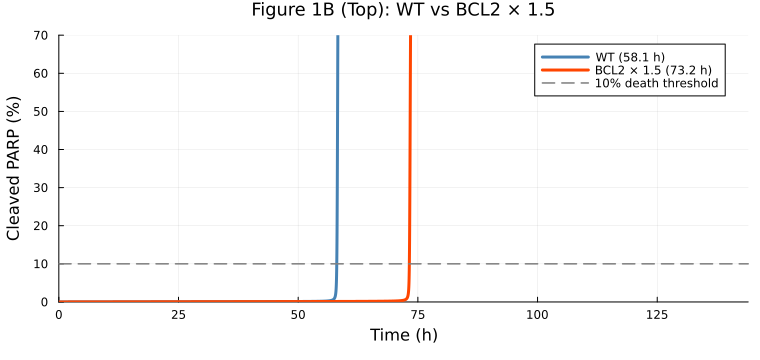

In [3]:
res_wt   = run_apoptosis(1.0)
res_bcl2 = run_apoptosis(1.5)

println("WT time to cell death:         ", round(res_wt.t2d_hours, digits=1), " hours")
println("BCL2 × 1.5 time to cell death: ", round(res_bcl2.t2d_hours, digits=1), " hours")

p_top = plot(res_wt.t_hours, res_wt.cparp_pct, lw=3, color=:steelblue,
             label="WT ($(round(res_wt.t2d_hours, digits=1)) h)")
plot!(p_top, res_bcl2.t_hours, res_bcl2.cparp_pct, lw=3, color=:orangered,
      label="BCL2 × 1.5 ($(round(res_bcl2.t2d_hours, digits=1)) h)")
hline!(p_top, [10.0], linestyle=:dash, color=:gray, lw=1.5, label="10% death threshold")
plot!(p_top, xlabel="Time (h)", ylabel="Cleaved PARP (%)",
      title="Figure 1B (Top): WT vs BCL2 × 1.5", titlefontsize=12,
      xlims=(0, 144), ylims=(0, 70), grid=true, size=(760, 360))
p_top

---

## Step 4: Recreate Figure 1B (Bottom) — Scanning BCL2 (`1×` to `100×`)

Now let's scan **BCL2 overexpression** across `[1, 1.5, 2, 5, 10, 50, 100]` to recreate the horizontal bar chart in **Figure 1B** of *Norris et al.* (2024).

Clinically, lymphoma cells with a *BCL2* translocation (`t(14;18)`) often express many-fold more BCL2 protein than normal B-cells. Watch what happens to time to cell death as the BCL2 multiplier increases!

Row,BCL2_Multiplier,Time_to_Death_h,Status
,Float64,Float64,String
1,1.0,58.1,Died
2,1.5,73.2,Died
3,2.0,81.8,Died
4,5.0,144.0,Survived (>144 h)
5,10.0,144.0,Survived (>144 h)
6,50.0,144.0,Survived (>144 h)
7,100.0,144.0,Survived (>144 h)


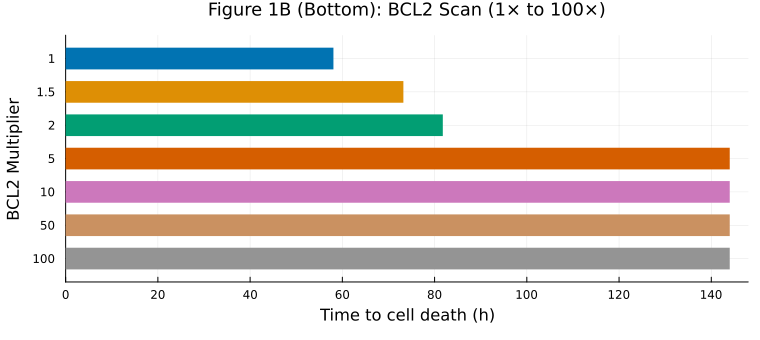

In [4]:
bcl2_mults = [1.0, 1.5, 2.0, 5.0, 10.0, 50.0, 100.0]
t2d_hours  = Float64[]
survived   = Bool[]

for mult in bcl2_mults
    res = run_apoptosis(mult)
    push!(t2d_hours, res.t2d_hours)
    push!(survived, res.survived)
end

display(DataFrame(
    BCL2_Multiplier = bcl2_mults,
    Time_to_Death_h = round.(t2d_hours, digits=1),
    Status          = [s ? "Survived (>144 h)" : "Died" for s in survived],
))

cA = palette(:seaborn_colorblind)
labels_y   = ["1", "1.5", "2", "5", "10", "50", "100"]
bar_colors = [cA[1], cA[2], cA[3], cA[4], cA[5], cA[6], cA[8]]

bar(
    1:length(bcl2_mults), t2d_hours;
    orientation = :horizontal,
    yflip       = true,
    bar_width   = 0.65,
    yticks      = (1:length(bcl2_mults), labels_y),
    ylims       = (0.3, length(bcl2_mults) + 0.7),
    fillcolor   = bar_colors,
    linecolor   = :transparent,
    legend      = false,
    xlims       = (0, 148),
    xticks      = 0:20:140,
    xlabel      = "Time to cell death (h)",
    ylabel      = "BCL2 Multiplier",
    title       = "Figure 1B (Bottom): BCL2 Scan (1× to 100×)",
    titlefontsize = 12,
    size        = (760, 340),
)

Notice the non-linear clinical threshold:
- From `1×` to `2×` BCL2, cell death is progressively delayed (`58.1 h` at `1×` WT, `73.2 h` at `1.5×`, and `81.8 h` at `2×`).
- By `5×` BCL2 and above (`5×`, `10×`, `50×`, `100×`), mitochondrial BCL2 buffers all incoming `tBid`/`BAX` before MOMP can trigger — the cell survives the entire 144-hour exposure.

---

## Interactive Exercises

### Exercise 1: Pinpoint the BCL2 Survival Threshold

In the scan above, `BCL2 × 2` dies at `81.8` hours while `BCL2 × 5` survives past `144` hours.

**Your task:** Edit `fine_bcl2` below to scan multipliers between `2.0` and `5.0` (for example `2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0`) and find where the cell crosses from delayed death to complete resistance (`> 144 h`).

In [5]:
# Exercise 1: Edit fine_bcl2 to scan between 2.0 and 5.0 and find the survival threshold!
fine_bcl2 = [2.0, 5.0]

fine_t2d  = Float64[]
fine_surv = Bool[]
for m in fine_bcl2
    r = run_apoptosis(m)
    push!(fine_t2d, r.t2d_hours)
    push!(fine_surv, r.survived)
end

display(DataFrame(
    BCL2_Multiplier = fine_bcl2,
    Time_to_Death_h = round.(fine_t2d, digits=1),
    Status          = [s ? "Survived (>144 h)" : "Died" for s in fine_surv],
))

Row,BCL2_Multiplier,Time_to_Death_h,Status
,Float64,Float64,String
1,2.0,81.8,Died
2,5.0,144.0,Survived (>144 h)


````{admonition} Hint
:class: dropdown tip

Replace `fine_bcl2 = [2.0, 5.0]` with `fine_bcl2 = [2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]` and run the cell.
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
fine_bcl2 = [2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]

fine_t2d  = Float64[]
fine_surv = Bool[]
for m in fine_bcl2
    r = run_apoptosis(m)
    push!(fine_t2d, r.t2d_hours)
    push!(fine_surv, r.survived)
end

display(DataFrame(
    BCL2_Multiplier = fine_bcl2,
    Time_to_Death_h = round.(fine_t2d, digits=1),
    Status          = [s ? "Survived (>144 h)" : "Died" for s in fine_surv],
))
```

At `4.0×` BCL2 the cell still dies at `97.6 h`, whereas by `4.5×` BCL2 it survives past the 144-hour window — showing how sharply a cell switches from delayed apoptosis to complete resistance once BCL2 exceeds the capacity of incoming `tBid`/`BAX`.
````

---

### Exercise 2: Rescue BCL2 Resistance (`BCL2 × 2.0`) — Comparing Pathway Targets

In clinical oncology, drugs can target different points in the apoptosis pathway:
- **Venetoclax** directly inhibits **BCL2** at the mitochondria (`"k1_88"`).
- Pro-apoptotic activators such as **BAX** (`"k1_86"`) or **BID** (`"k1_81"`) push directly against the BCL2 brake at MOMP.
- **SMAC mimetics** inhibit **XIAP** downstream of the mitochondria (`"k1_95"`), lowering the safety clamp on Caspase-3.

| Gene / Protein | Role in Apoptosis | Parameter Name in `modify` | Direction to Promote Death |
| :--- | :--- | :--- | :--- |
| **BAX** | Pro-apoptotic mitochondrial pore former | `"k1_86"` | Over-express (e.g. `2.0` – `2.5`) |
| **BID** | Pro-apoptotic BH3-only activator (`tBid`) | `"k1_81"` | Over-express (e.g. `2.0` – `2.5`) |
| **BCL2 (mitochondrial)** | Anti-apoptotic MOMP brake *(venetoclax target)* | `"k1_88"` | Inhibit (e.g. `0.5`) |
| **Bcl2c (cytosolic)** | Anti-apoptotic cytosolic `tBid` buffer | `"k1_83"` | Inhibit (e.g. `0.5`) |
| **XIAP** | Downstream Caspase-3/9 brake *(SMAC mimetic target)* | `"k1_95"` | Inhibit (e.g. `0.5` — watch `t = 0`!) |
| **FLIP** | Anti-apoptotic Caspase-8 inhibitor at DISC | `"k1_73"` | Inhibit (e.g. `0.2` – `0.5`) |

**Your task:** Edit `rescue_mods` below to test whether inhibiting **BCL2** (`"k1_88"`), over-expressing **BAX** (`"k1_86"`), or inhibiting downstream **XIAP** (`"k1_95"`) restores WT-like apoptosis timing (`~58.1 h`) in a `BCL2 × 2.0` lymphoma cell — and watch what happens at `t = 0 h` when you remove the downstream XIAP brake!

Row,Condition,Time_to_Death_h,Status
,String,Float64,String
1,WT,58.1,Died
2,BCL2 × 2.0 (untreated),81.8,Died
3,BCL2 × 2.0 + My Rescue,81.8,Died


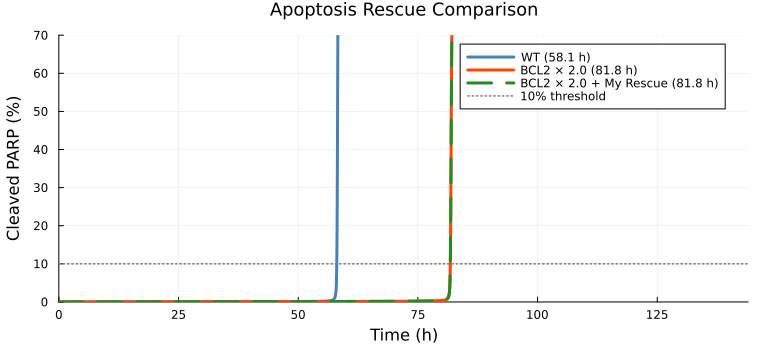

In [6]:
# Exercise 2: Edit rescue_mods below to rescue BCL2 x 2.0 back toward WT (~58.1 h)!
test_bcl2   = 2.0
rescue_name = "BCL2 × 2.0 + My Rescue"
rescue_mods = Dict{String, Float64}()   # <-- Try Dict("k1_88" => 0.5), Dict("k1_86" => 2.0), or Dict("k1_95" => 0.5)

r_wt     = run_apoptosis(1.0)
r_mut    = run_apoptosis(test_bcl2)
r_rescue = run_apoptosis(test_bcl2; mods=rescue_mods)

display(DataFrame(
    Condition       = ["WT", "BCL2 × $(test_bcl2) (untreated)", rescue_name],
    Time_to_Death_h = round.([r_wt.t2d_hours, r_mut.t2d_hours, r_rescue.t2d_hours], digits=1),
    Status          = [r.survived ? "Survived (>144 h)" : "Died" for r in (r_wt, r_mut, r_rescue)],
))

p_ex = plot(r_wt.t_hours, r_wt.cparp_pct, lw=3, color=:steelblue,
            label="WT ($(round(r_wt.t2d_hours, digits=1)) h)")
plot!(p_ex, r_mut.t_hours, r_mut.cparp_pct, lw=3, color=:orangered,
      label="BCL2 × $(test_bcl2) ($(round(r_mut.t2d_hours, digits=1)) h)")
plot!(p_ex, r_rescue.t_hours, r_rescue.cparp_pct, lw=3, linestyle=:dash, color=:forestgreen,
      label="$(rescue_name) ($(round(r_rescue.t2d_hours, digits=1)) h)")
hline!(p_ex, [10.0], linestyle=:dot, color=:gray, lw=1.5, label="10% threshold")
plot!(p_ex, xlabel="Time (h)", ylabel="Cleaved PARP (%)",
      title="Apoptosis Rescue Comparison", titlefontsize=12,
      xlims=(0, 144), ylims=(0, 70), size=(760, 360))
p_ex

````{admonition} Hint
:class: dropdown tip

Compare mitochondrial checkpoint targets like `Dict("k1_88" => 0.5)` (mimicking venetoclax) or `Dict("k1_86" => 2.0)` (BAX overexpression) against `Dict("k1_95" => 0.5)` (XIAP inhibition). Notice whether the cell stays alive at `t = 0 h` (resting steady state, `L = 0`) before death ligand is added!
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
test_bcl2 = 2.0
candidates = [
    ("WT",                      1.0,       Dict{String, Float64}()),
    ("BCL2 × 2 (untreated)",    test_bcl2, Dict{String, Float64}()),
    ("+ BCL2 inh (venetoclax)", test_bcl2, Dict("k1_88" => 0.5)),
    ("+ BAX OE (2.0×)",         test_bcl2, Dict("k1_86" => 2.0)),
    ("+ BID OE (2.0×)",         test_bcl2, Dict("k1_81" => 2.0)),
    ("+ XIAP inh (0.5×)",       test_bcl2, Dict("k1_95" => 0.5)),
]

res_list = [(name, run_apoptosis(m; mods=d)) for (name, m, d) in candidates]
display(DataFrame(
    Condition       = [x[1] for x in res_list],
    Time_to_Death_h = [round(x[2].t2d_hours, digits=1) for x in res_list],
))

p_sol = plot(xlabel="Time (h)", ylabel="Cleaved PARP (%)",
             title="Rescue Targets for BCL2 × 2.0", titlefontsize=12,
             xlims=(0, 144), ylims=(0, 70), legend=:bottomright, size=(760, 360))
for (name, r) in res_list
    plot!(p_sol, r.t_hours, r.cparp_pct, lw=2.5, label="$(name) ($(round(r.t2d_hours, digits=1)) h)")
end
hline!(p_sol, [10.0], linestyle=:dot, color=:gray, lw=1.2, label="10% threshold")
p_sol
```

- Rebalancing the mitochondrial **BCL2 : BAX / BID** checkpoint (`"k1_88" => 0.5` → `58.1 h`, `"k1_86" => 2.0` → `60.3 h`, `"k1_81" => 2.0` → `56.9 h`) restores clean, ligand-triggered death right back to wild-type (`58.1 h`) while keeping the cell viable at rest (`t = 0 h`).
- By contrast, reducing downstream **XIAP** (`"k1_95" => 0.5`) drops the Caspase-3 threshold so low that basal caspase activity cleaves PARP *during resting steady state* (`0.0 h`, before death ligand is even added) — illustrating the clinical toxicity risk of removing downstream caspase brakes indiscriminately.
````

Now move on to **[2. Cell Cycle Timing & Scanning c-MYC (Norris *et al.* Figure 1E)](./02-cell-cycle-myc-figure1e.ipynb)** to model the second half of Double-Hit Lymphoma!